# EX 8 – Train a Simple Autoencoder for Dimensionality Reduction and Feature Learning
**Name:** Nishanth P  |  **Roll No:** 24BAD405  |  **Date:** 30-Oct-2026

**Aim:** To implement and train a simple autoencoder on MNIST, learn a lower-dimensional (32-D) representation, and evaluate it by reconstructing images and visualizing latent features.

## Pre-Lab Questions

## Part A: Dataset Preparation and Preprocessing

In [1]:
# Student details
STUDENT_NAME = "Nishanth P"
ROLL_NO      = "24BAD405"
DATE         = "30-Oct-2026"
print(f"Name: {STUDENT_NAME} | Roll No: {ROLL_NO} | Date: {DATE}")

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model

np.random.seed(47); tf.random.set_seed(47)
print("TensorFlow version:", tf.__version__)

Name: Nishanth P | Roll No: 24BAD405 | Date: 30-Oct-2026


I0000 00:00:1793528980.172135   27771 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793528980.180694   27771 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793528980.812960   27771 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793528985.069846   27771 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

TensorFlow version: 2.22.0-rc0


[24BAD405] Training images: (60000, 28, 28)
[24BAD405] Testing images : (10000, 28, 28)
[24BAD405] Image dimension: (28, 28) | Pixel range: 0 - 255


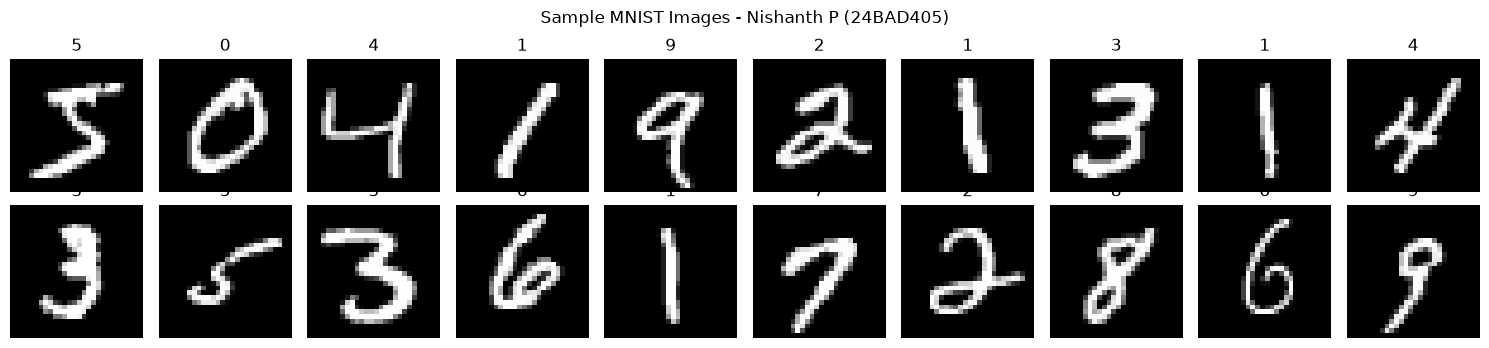

In [2]:
# Load MNIST
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print(f"[{ROLL_NO}] Training images:", x_train.shape)
print(f"[{ROLL_NO}] Testing images :", x_test.shape)
print(f"[{ROLL_NO}] Image dimension:", x_train.shape[1:], "| Pixel range:", x_train.min(), "-", x_train.max())

# Display sample images
fig, axes = plt.subplots(2, 10, figsize=(15, 3.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i], cmap="gray"); ax.set_title(str(y_train[i])); ax.axis("off")
plt.suptitle(f"Sample MNIST Images - {STUDENT_NAME} ({ROLL_NO})")
plt.tight_layout(); plt.show()

In [3]:
# Normalize to [0,1] and flatten 28x28 -> 784
x_train = x_train.astype("float32") / 255.0
x_test  = x_test.astype("float32")  / 255.0
x_train_flat = x_train.reshape(len(x_train), -1)
x_test_flat  = x_test.reshape(len(x_test), -1)

print(f"[{ROLL_NO}] Flattened train:", x_train_flat.shape)
print(f"[{ROLL_NO}] Flattened test :", x_test_flat.shape)
print(f"[{ROLL_NO}] Pixel range after normalization: {x_train_flat.min()} - {x_train_flat.max()}")
# Autoencoder: input = target (x_train_flat, x_train_flat)

[24BAD405] Flattened train: (60000, 784)
[24BAD405] Flattened test : (10000, 784)
[24BAD405] Pixel range after normalization: 0.0 - 1.0


## Part B: Implementing the Encoder and Decoder

In [4]:
INPUT_DIM, LATENT_DIM = 784, 32

# Encoder
enc_in = keras.Input(shape=(INPUT_DIM,), name="encoder_input")
x = layers.Dense(128, activation="relu")(enc_in)
x = layers.Dense(64,  activation="relu")(x)
latent = layers.Dense(LATENT_DIM, activation="relu", name="latent_vector")(x)
encoder = Model(enc_in, latent, name=f"encoder_{ROLL_NO}")

# Decoder
dec_in = keras.Input(shape=(LATENT_DIM,), name="decoder_input")
y = layers.Dense(64,  activation="relu")(dec_in)
y = layers.Dense(128, activation="relu")(y)
dec_out = layers.Dense(INPUT_DIM, activation="sigmoid", name="reconstruction")(y)
decoder = Model(dec_in, dec_out, name=f"decoder_{ROLL_NO}")

# Autoencoder = decoder(encoder(input))
ae_in = keras.Input(shape=(INPUT_DIM,))
autoencoder = Model(ae_in, decoder(encoder(ae_in)), name=f"autoencoder_{ROLL_NO}")

print(f"--- {STUDENT_NAME} ({ROLL_NO}) ---")
encoder.summary()
decoder.summary()
autoencoder.summary()

E0000 00:00:1793528991.134884   27771 cuda_executor.cc:1690] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:68

W0000 00:00:1793528991.136359   27809 cuda_executor.cc:1710] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:77
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:107
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:112

W0000 00:00:1793528991.168843   27771 dlopen_checker.cc:38] Could not load dynamic library 'libcudart.so.12'; dlerror: libcudart.so.12: cannot open shared object file: No such file or directory
W0000 00:00:1793528991.168906   2777

--- Nishanth P (24BAD405) ---


Model: "encoder_24BAD405"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_vector (Dense)           │ (None, 32)             │         2,080 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,816 (432.88 KB)

 Trainable params: 110,816 (432.88 KB)

... (7 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_24BAD405 (Functional)   │ (None, 32)             │       110,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_24BAD405 (Functional)   │ (None, 784)            │       111,568 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 222,384 (868.69 KB)

 Trainable params: 222,384 (868.69 KB)

 Non-trainable params: 0 (0.00 B)

## Part C: Compiling and Training the Autoencoder

In [5]:
autoencoder.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                    loss="binary_crossentropy",
                    metrics=["mse"])

history = autoencoder.fit(x_train_flat, x_train_flat,
                          epochs=10, batch_size=256, shuffle=True,
                          validation_data=(x_test_flat, x_test_flat), verbose=1)
print(f"[{ROLL_NO}] Training complete.")

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 9s 29ms/step - loss: 0.2516 - mse: 0.0631 - val_loss: 0.1727 - val_mse: 0.0370
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - loss: 0.1512 - mse: 0.0295 - val_loss: 0.1354 - val_mse: 0.0243
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 0.1305 - mse: 0.0225 - val_loss: 0.1241 - val_mse: 0.0204
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - loss: 0.1213 - mse: 0.0195 - val_loss: 0.1159 - val_mse: 0.0178
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.1149 - mse: 0.0173 - val_loss: 0.1109 - val_mse: 0.0161
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.1107 - mse: 0.0160 - val_loss: 0.1076 - val_mse: 0.0150
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - loss: 0.1075 - mse: 0.0149 - val_loss: 0.1048 - val_mse: 0.0141
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.1050 - mse: 0.0141 - val_loss: 0.1027 - val_mse: 0.0134
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/

Epoch  1 | train loss = 0.2516 | val loss = 0.1727
Epoch  2 | train loss = 0.1512 | val loss = 0.1354
Epoch  3 | train loss = 0.1305 | val loss = 0.1241
Epoch  4 | train loss = 0.1213 | val loss = 0.1159
Epoch  5 | train loss = 0.1149 | val loss = 0.1109
Epoch  6 | train loss = 0.1107 | val loss = 0.1076
Epoch  7 | train loss = 0.1075 | val loss = 0.1048
Epoch  8 | train loss = 0.1050 | val loss = 0.1027
Epoch  9 | train loss = 0.1031 | val loss = 0.1010
Epoch 10 | train loss = 0.1015 | val loss = 0.0997


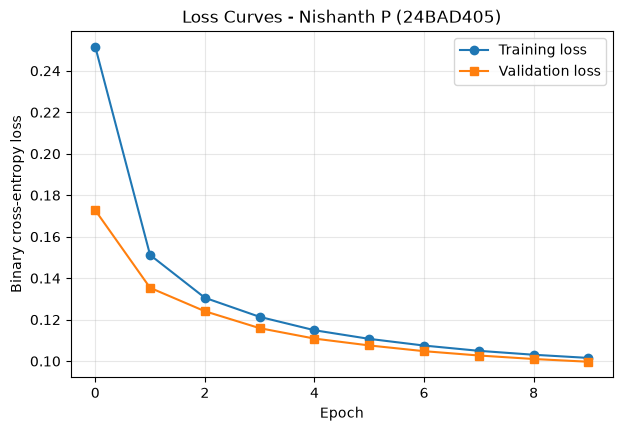

[24BAD405] Test BCE loss: 0.0997 | Test MSE: 0.01244


In [6]:
# Loss values per epoch
for e,(tl,vl) in enumerate(zip(history.history["loss"], history.history["val_loss"]),1):
    print(f"Epoch {e:2d} | train loss = {tl:.4f} | val loss = {vl:.4f}")

plt.figure(figsize=(7,4.5))
plt.plot(history.history["loss"], marker="o", label="Training loss")
plt.plot(history.history["val_loss"], marker="s", label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Binary cross-entropy loss")
plt.title(f"Loss Curves - {STUDENT_NAME} ({ROLL_NO})")
plt.legend(); plt.grid(alpha=.3); plt.show()

test_loss, test_mse = autoencoder.evaluate(x_test_flat, x_test_flat, verbose=0)
print(f"[{ROLL_NO}] Test BCE loss: {test_loss:.4f} | Test MSE: {test_mse:.5f}")

## Part D: Dimensionality Reduction, Feature Learning and Reconstruction

In [7]:
latent_test = encoder.predict(x_test_flat, verbose=0)
reconstructed = decoder.predict(latent_test, verbose=0)

print(f"[{ROLL_NO}] Original input dimension : {x_test_flat.shape[1]}")
print(f"[{ROLL_NO}] Latent dimension         : {latent_test.shape[1]}")
print(f"[{ROLL_NO}] Compression ratio        : {x_test_flat.shape[1]/latent_test.shape[1]:.1f}x")
print(f"[{ROLL_NO}] Reconstructed shape      : {reconstructed.shape}")
print("Sample latent vector (first image):\n", np.round(latent_test[0], 3))

[24BAD405] Original input dimension : 784
[24BAD405] Latent dimension         : 32
[24BAD405] Compression ratio        : 24.5x
[24BAD405] Reconstructed shape      : (10000, 784)
Sample latent vector (first image):
 [10.586 12.011  7.08  11.81   6.662  0.    16.424  6.827  8.67  15.388
 19.344  6.304 10.777  6.207  4.238 14.039  0.    15.9   21.536  4.983
 11.225 12.636 10.12   7.409  8.628 14.677  0.     6.381 11.375  7.778
 16.341 22.346]


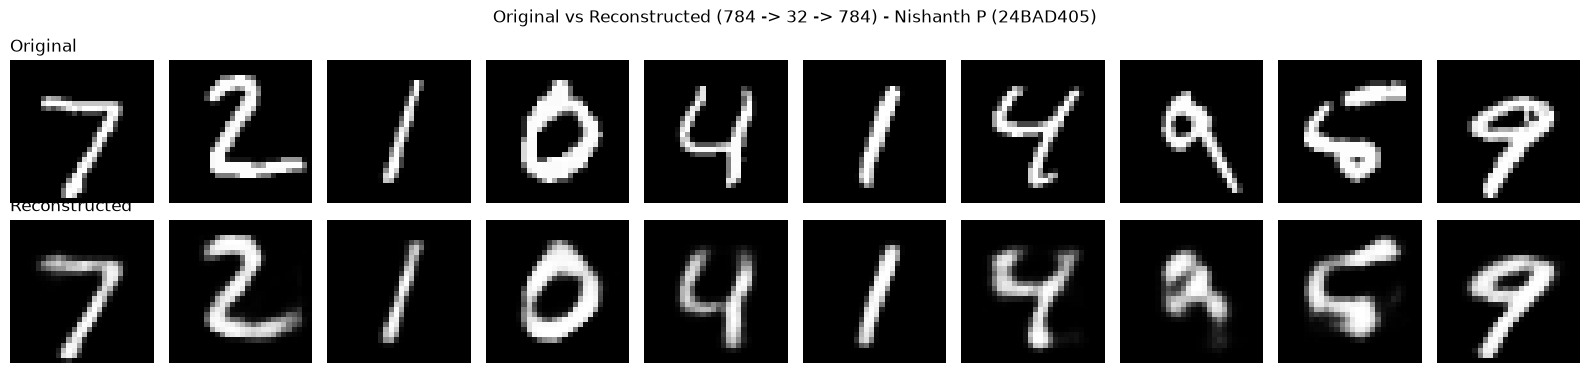

[24BAD405] Mean per-image MSE: 0.01244 (best 0.00073, worst 0.05294)


In [8]:
# Original vs reconstructed
n = 10
fig, axes = plt.subplots(2, n, figsize=(16, 3.8))
for i in range(n):
    axes[0,i].imshow(x_test_flat[i].reshape(28,28), cmap="gray"); axes[0,i].axis("off")
    axes[1,i].imshow(reconstructed[i].reshape(28,28), cmap="gray"); axes[1,i].axis("off")
axes[0,0].set_title("Original", loc="left"); axes[1,0].set_title("Reconstructed", loc="left")
plt.suptitle(f"Original vs Reconstructed (784 -> 32 -> 784) - {STUDENT_NAME} ({ROLL_NO})")
plt.tight_layout(); plt.show()

per_img_mse = np.mean((x_test_flat - reconstructed)**2, axis=1)
print(f"[{ROLL_NO}] Mean per-image MSE: {per_img_mse.mean():.5f} (best {per_img_mse.min():.5f}, worst {per_img_mse.max():.5f})")

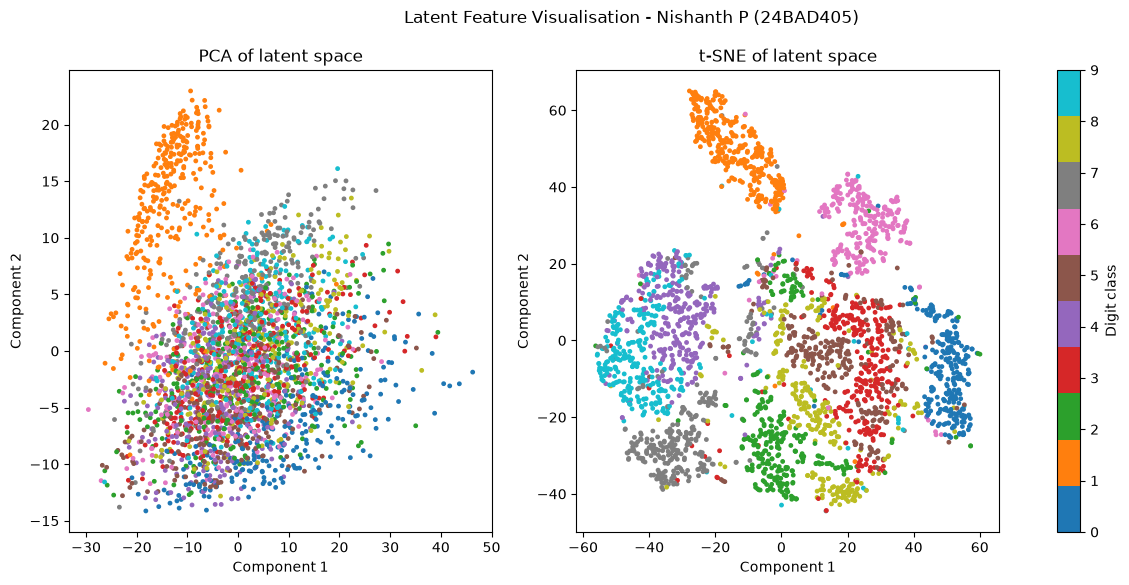

In [9]:
# Latent features visualised in 2-D using PCA and t-SNE
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

N = 3000
lat, lab = latent_test[:N], y_test[:N]

pca2 = PCA(n_components=2).fit_transform(lat)
tsne2 = TSNE(n_components=2, perplexity=30, random_state=47, init="pca").fit_transform(lat)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, data, t in zip(axes, [pca2, tsne2], ["PCA of latent space", "t-SNE of latent space"]):
    sc = ax.scatter(data[:,0], data[:,1], c=lab, cmap="tab10", s=6)
    ax.set_title(t); ax.set_xlabel("Component 1"); ax.set_ylabel("Component 2")
fig.colorbar(sc, ax=axes, label="Digit class")
plt.suptitle(f"Latent Feature Visualisation - {STUDENT_NAME} ({ROLL_NO})")
plt.show()

In [10]:
# Save models and reconstructed images
autoencoder.save(f"autoencoder_{ROLL_NO}.keras")
encoder.save(f"encoder_{ROLL_NO}.keras")
decoder.save(f"decoder_{ROLL_NO}.keras")
np.save(f"reconstructed_{ROLL_NO}.npy", reconstructed[:100])
print(f"[{ROLL_NO}] Saved models and reconstructed images.")

[24BAD405] Saved models and reconstructed images.
